In [2]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score,mean_squared_error
from sklearn.datasets import fetch_california_housing

In [3]:
data=fetch_california_housing()
print(data.feature_names)

['MedInc', 'HouseAge', 'AveRooms', 'AveBedrms', 'Population', 'AveOccup', 'Latitude', 'Longitude']


In [4]:
X=data.data[:,2]

In [5]:
y=data.target

In [6]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.2,random_state=42)

In [7]:
m=0
c=0
learning_rate=0.001
n=len(X_train)
for i in range (1000):
    y_pred=m*X_train+c
    dm=(-2/n)*np.sum(X_train*(y_train-y_pred))
    dc=(-2/n)*np.sum(y_train-y_pred)
    m-=learning_rate*dm
    c-=learning_rate*dc
y_pred_gd=m*X_test+c
print("Slope:",m)
print("Intercept:",c)
print("Mean Squared Error:", mean_squared_error(y_test, y_pred_gd))
print("R2 Score:", r2_score(y_test, y_pred_gd))

Slope: 0.25797761849057654
Intercept: 0.4850206129374197
Mean Squared Error: 1.6449229482854868
R2 Score: -0.2552744796465303


In [9]:
ones=np.ones(len(X_train))
X_matrix=np.column_stack((ones,X_train))
theta=np.linalg.inv(X_matrix.T @ X_matrix)@(X_matrix.T @ y_train)
ones_test=np.ones(len(X_test))
X_test_matrix=np.column_stack((ones_test,X_test))
y_predict=X_test_matrix @theta
print(mean_squared_error(y_test,y_predict))
print(r2_score(y_test,y_predict))

1.2923314440807283
0.013795337532286012


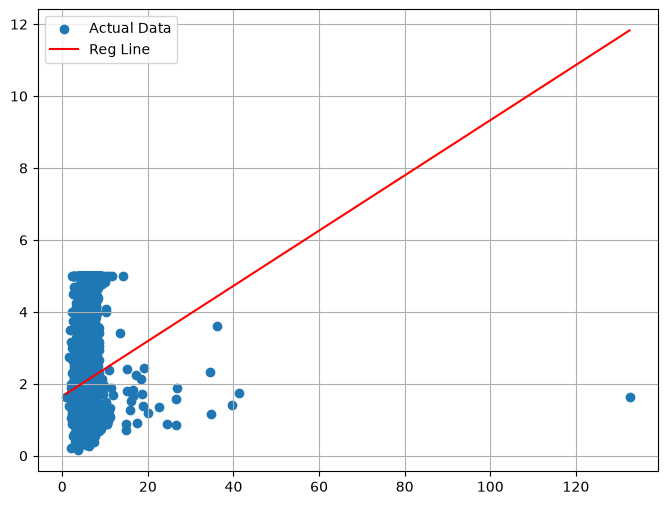

In [12]:
import matplotlib.pyplot as plt
plt.figure(figsize=(8,6))
plt.scatter(X_test,y_test,label="Actual Data")
x_line=np.linspace(min(X_test),max(X_test),100)
plt.plot(x_line,theta[0]+theta[1]*x_line,color="red",label="Reg Line")
plt.legend()
plt.grid(True)
plt.show()